# A guidance-scale sweep on digits

Booster LEAP, Diffusion Models, topic 6. You train a small class-conditional diffusion model on digit pictures, then measure what the guidance scale does to variety and fidelity, how much the numbers move with the random seed, what happens without label dropout, and how editing strength and inpainting behave.

<h1 style="color:#b45309">&#9888; First: File &rarr; Save a copy in Drive</h1>

<span style="font-size:20px">This notebook is read-only. Make your own copy now, then work in the copy (no GitHub login needed).</span>

**How to use this notebook:** run the cells from top to bottom (Runtime, Run all, or Shift+Enter on each cell). It needs no GPU and no downloads except the small `diffusers` library (installed by the first code cell if it is missing). The two training cells take a few minutes each on a CPU and save their weights to a file, so a second run is fast. Change one thing at a time and run again; the last cell tells you what to try.

**What you need to know first:** nothing about diffusion beyond lessons 1 and 3 of this topic. Two ideas help: *guidance* pushes a sample toward its label by exaggerating the difference between the guess with the label and the guess without it, and a *judge* is a separate classifier that only reads the pictures we generate. Everything else is explained where it appears.

In [ ]:
try:
    import diffusers
except ImportError:                                     # Colab has torch, scikit-learn and matplotlib, but not always diffusers
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "diffusers"])
    import diffusers
import torch
print("torch", torch.__version__, "diffusers", diffusers.__version__, "- runs on the CPU")

torch 2.14.0+cpu diffusers 0.43.0 - runs on the CPU


## 1. Guidance on two clusters, exactly

The exact denoiser of two clusters (no training) lets you see guidance in its purest form: with the condition 'right' the samples fall into the right cluster; as the scale $w$ grows they get narrower and move outward, and at a high scale they leave the cluster altogether (lesson 3).

In [ ]:
# The exact denoiser of two clusters (lesson 3): no training. Change S (the spread of each cluster) and CENTRE and run again.
import math, random
T = 1000
AB = [1.0]
for i in range(T):
    AB.append(AB[-1] * (1 - (1e-4 + (0.02 - 1e-4) * i / (T - 1))))
S = 0.5
CENTRE = {"left": -2.0, "right": 2.0}

def eps_one(x, t, name):
    ab = AB[t]
    return (x - math.sqrt(ab) * CENTRE[name]) / (ab * S * S + 1 - ab) * math.sqrt(1 - ab)

def eps_free(x, t):
    ab = AB[t]
    var = ab * S * S + 1 - ab
    h = {n: math.exp(-(x - math.sqrt(ab) * m) ** 2 / (2 * var)) for n, m in CENTRE.items()}
    z = sum(h.values())
    return sum(h[n] / z * eps_one(x, t, n) for n in CENTRE)

def sample_clusters(cond, w, n=400, steps=50, seed=0):
    rng = random.Random(seed)
    ts = [round(999 - i * 999 / (steps - 1)) for i in range(steps)]
    out = []
    for _ in range(n):
        x = rng.gauss(0, 1)
        for i, t in enumerate(ts):
            e_f = eps_free(x, t)
            e = e_f + w * (eps_one(x, t, cond) - e_f)
            ab, ab_prev = AB[t + 1], (AB[ts[i + 1] + 1] if i + 1 < len(ts) else 1.0)
            x0 = (x - math.sqrt(1 - ab) * e) / math.sqrt(ab)
            x = math.sqrt(ab_prev) * x0 + math.sqrt(1 - ab_prev) * e
        out.append(x)
    return out

print("  w     mean   spread   inside the cluster (within 1.5)")
for w in (0, 1, 2, 4, 8, 16):
    o = sample_clusters("right", w)
    m = sum(o) / len(o)
    print(f"{w:3d} {m:+8.3f} {math.sqrt(sum((v - m) ** 2 for v in o) / len(o)):8.3f} {sum(1 for v in o if abs(v - 2) <= 1.5) / len(o):14.3f}")

  w     mean   spread   inside the cluster (within 1.5)
  0   -0.076    2.048          0.475
  1   +1.994    0.485          0.998
  2   +2.316    0.350          0.998
  4   +2.665    0.282          0.993
  8   +3.102    0.239          0.927
 16   +3.677    0.210          0.210


## 2. A class-conditional model on digits

The 1,797 digit pictures of $8\times8$ pixels, a judge classifier that only reads generated pictures, and a small U-Net with a label embedding. For one training example in ten the label is replaced by 'no label', so the same network also learns the unconditional guess (lessons 1 and 3). The cell trains for about four minutes on a CPU and saves `t06_class.pt`; a second run loads it.

In [ ]:
import math, os, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from diffusers import UNet2DModel, DDIMScheduler

torch.manual_seed(0)
d = load_digits()
X = torch.tensor(d.images, dtype=torch.float32)[:, None] / 16 * 2 - 1            # 1797 digits, 1 channel, 8 x 8, values -1 .. 1
Y = torch.tensor(d.target)
train_x, test_x, train_y, test_y = X[:1500], X[1500:], Y[:1500], Y[1500:]
judge = LogisticRegression(max_iter=2000).fit(train_x.flatten(1).numpy(), train_y.numpy())   # a separate classifier that only judges generated digits
NULL = 10                                                                          # label 10 means "no label" (used for guidance)
SCHED_CFG = dict(num_train_timesteps=1000, beta_start=1e-4, beta_end=0.02, beta_schedule="linear", clip_sample=False, prediction_type="epsilon")

def count(m):
    return sum(p.numel() for p in m.parameters())

def make_class_unet():                          # a denoiser that also receives a class label: the label becomes a vector that is ADDED to the time embedding
    return UNet2DModel(sample_size=8, in_channels=1, out_channels=1, down_block_types=("DownBlock2D", "AttnDownBlock2D"), up_block_types=("AttnUpBlock2D", "UpBlock2D"),
                       block_out_channels=(32, 64), layers_per_block=1, num_class_embeds=11, norm_num_groups=8, attention_head_dim=8)

sched = DDIMScheduler(**SCHED_CFG)
def train_class_unet(steps=3000, drop=0.1, seed=0):
    torch.manual_seed(seed)
    unet = make_class_unet()
    opt = torch.optim.Adam(unet.parameters(), 1e-3)
    sc = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for s in range(steps):
        i = torch.randint(0, 1500, (64,))
        x0, y = train_x[i], train_y[i].clone()
        y[torch.rand(64) < drop] = NULL                    # for 1 example in 10 the label is hidden: the SAME network also learns the unconditional case
        t = torch.randint(0, 1000, (64,))
        eps = torch.randn_like(x0)
        xt = sched.add_noise(x0, eps, t)                   # the closed form of topic 2
        loss = F.mse_loss(unet(xt, t, class_labels=y).sample, eps)
        opt.zero_grad(); loss.backward(); opt.step(); sc.step()
    return unet

if os.path.exists("t06_class.pt"):                         # trained once (about two minutes on a CPU), then reused
    unet = make_class_unet(); unet.load_state_dict(torch.load("t06_class.pt"))
else:
    unet = train_class_unet()
    torch.save(unet.state_dict(), "t06_class.pt")
unet.eval()
print("class-conditional U-Net:", f"{count(unet):,d}", "parameters; label embedding table", tuple(unet.class_embedding.weight.shape))

class-conditional U-Net: 702,753 parameters; label embedding table (11, 128)


### The sampler

`sample` runs the DDIM loop of topic 3 with the guidance formula `e = e_free + w * (e_cond - e_free)`; `report` prints three numbers for a set of generated pictures: how often the judge reads the wanted digit (fidelity), how alike two pictures of the same digit are (diversity; smaller means more alike) and how many pixel values leave the allowed range -1 to 1 (a sign of over-sharpened pictures).

In [ ]:
# the sampler of a conditional model: eps_fn(z, t, cond) returns the noise guess WITH (cond=True) or WITHOUT the condition (cond=False)
@torch.no_grad()
def sample(eps_fn, shape, n, w=1.0, steps=20, seed=0, scheduler=None, init=None, strength=1.0, known=None, mask=None):
    # init + strength: start from a noised copy of a picture instead of pure noise (editing, lesson 6)
    # known + mask: after every step put the noised KNOWN pixels back where mask is 0 (inpainting, lesson 6)
    sch = scheduler or DDIMScheduler(**SCHED_CFG)
    sch.set_timesteps(steps)
    g = torch.Generator().manual_seed(seed)
    ts = sch.timesteps[int(round(steps * (1 - strength))):]
    z = torch.randn((n,) + shape, generator=g)
    fixed = torch.randn((n,) + shape, generator=g)                  # the noise that is added to the known pixels
    if init is not None:
        z = sch.add_noise(init, z, ts[:1].repeat(n))                # the picture, noised up to the step where we start
    for i, t in enumerate(ts):
        e_c = eps_fn(z, t, True)
        if w != 1.0:                                                # classifier-free guidance (lesson 3): w = 1 is plain conditioning
            e_u = eps_fn(z, t, False)
            e_c = e_u + w * (e_c - e_u)
        z = sch.step(e_c, t, z).prev_sample
        if known is not None:
            keep = sch.add_noise(known, fixed, ts[i + 1:i + 2].repeat(n)) if i + 1 < len(ts) else known
            z = mask * z + (1 - mask) * keep
    return z

labels300 = torch.arange(300) % 10                         # 30 pictures of every digit
@torch.no_grad()
def judge_probs(imgs):
    return torch.tensor(judge.predict_proba(imgs.clamp(-1, 1).flatten(1).numpy()))

def report(name, raw, labels=labels300):
    """fidelity = the judge sees the wanted digit; diversity = mean distance between two pictures of the same digit; out of range = share of pixel values beyond -1 .. 1"""
    img = raw.clamp(-1, 1)
    p = judge_probs(raw)
    fid = (p.argmax(1) == labels).float().mean().item()
    div = sum(torch.pdist(img[labels == k].flatten(1)).mean().item() for k in range(10)) / 10
    oor = (raw.abs() > 1).float().mean().item()
    print(f"{name:26s} shows the wanted digit {fid:6.1%}   judge confidence {p.max(1).values.mean():.3f}   diversity {div:5.2f}   out of range {oor:6.1%}")
    return fid, div, oor

def class_fn(labels):                                      # the class-conditional U-Net as an eps_fn: cond=False uses the "no label" row
    nul = torch.full_like(labels, NULL)
    return lambda z, t, cond: unet(z, t, class_labels=labels if cond else nul).sample

import matplotlib.pyplot as plt
import numpy as np

def show_rows(rows, titles, size=0.9):
    """rows: list of batches (n, 1, 8, 8) with values -1 .. 1; one row of pictures per batch"""
    n = len(rows[0])
    fig, ax = plt.subplots(len(rows), n, figsize=(n * size + 1.6, len(rows) * size + 0.2))
    ax = np.atleast_2d(ax)
    for r, batch in enumerate(rows):
        for k in range(n):
            ax[r, k].imshow(batch[k, 0].numpy(), cmap="gray_r", vmin=-1, vmax=1); ax[r, k].axis("off")
        ax[r, 0].text(-0.2, 0.5, titles[r], transform=ax[r, 0].transAxes, ha="right", va="center", fontsize=8)
    plt.tight_layout(); plt.show()

## 3. The guidance sweep

300 pictures for each scale (30 per digit).

In [ ]:
real_div = sum(torch.pdist(train_x[train_y == k][:30].flatten(1)).mean().item() for k in range(10)) / 10
print(f"real digits: diversity {real_div:.2f}")
WS = (0, 1, 1.5, 2, 3, 5, 8, 12, 20, 40)
table = {}
for w in WS:
    table[w] = report(f"w = {w:g}", sample(class_fn(labels300), (1, 8, 8), 300, float(w)))

real digits: diversity 4.06
w = 0                      shows the wanted digit   7.3%   judge confidence 0.807   diversity  5.55   out of range  18.4%
w = 1                      shows the wanted digit  99.7%   judge confidence 0.966   diversity  3.95   out of range  21.8%
w = 1.5                    shows the wanted digit 100.0%   judge confidence 0.994   diversity  3.68   out of range  28.3%
w = 2                      shows the wanted digit 100.0%   judge confidence 0.997   diversity  3.55   out of range  32.8%
w = 3                      shows the wanted digit 100.0%   judge confidence 0.998   diversity  3.44   out of range  38.8%
w = 5                      shows the wanted digit 100.0%   judge confidence 0.998   diversity  3.40   out of range  44.5%
w = 8                      shows the wanted digit 100.0%   judge confidence 0.999   diversity  3.55   out of range  50.3%
w = 12                     shows the wanted digit 100.0%   judge confidence 0.998   diversity  4.14   out of range  57

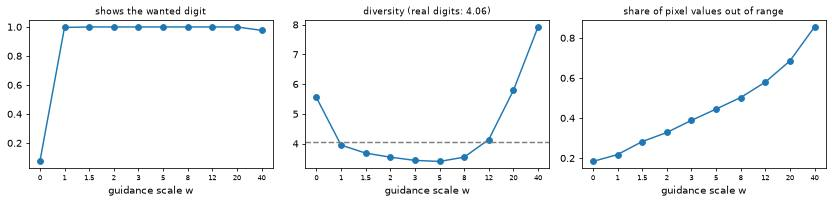

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, k, title in zip(ax, range(3), ["shows the wanted digit", "diversity (real digits: %.2f)" % real_div, "share of pixel values out of range"]):
    a.plot(range(len(WS)), [table[w][k] for w in WS], "o-")
    a.set_xticks(range(len(WS))); a.set_xticklabels([f"{w:g}" for w in WS], fontsize=7); a.set_xlabel("guidance scale w"); a.set_title(title, fontsize=9)
ax[1].axhline(real_div, color="gray", linestyle="--")
plt.tight_layout(); plt.show()

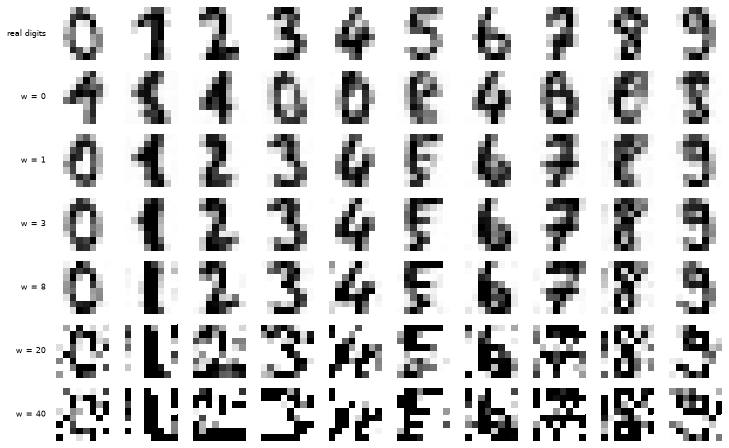

In [ ]:
ten = torch.arange(10)
real = torch.stack([test_x[test_y == k][0] for k in range(10)])
rows, titles = [real], ["real digits"]
for w in (0, 1, 3, 8, 20, 40):
    rows.append(sample(class_fn(ten), (1, 8, 8), 10, float(w), seed=2).clamp(-1, 1)); titles.append(f"w = {w}")
show_rows(rows, titles)

Read the table with lesson 3 in hand: fidelity saturates early, diversity falls first and then rises again when artefacts appear, and the out-of-range share grows steadily. Plain conditioning ($w = 1$) is already enough for this easy toy.

## 4. Is it chance? Three seeds

A row of numbers from one run is a single draw. The same sweep with three starting noises shows how far the numbers move by chance.

In [ ]:
print("seed     w   shows the wanted digit   diversity   out of range")
rows_ = {}
for seed in (0, 1, 2):
    for w in (1, 3, 8):
        raw = sample(class_fn(labels300), (1, 8, 8), 300, float(w), seed=seed)
        img = raw.clamp(-1, 1)
        fid = (judge_probs(raw).argmax(1) == labels300).float().mean().item()
        div = sum(torch.pdist(img[labels300 == k].flatten(1)).mean().item() for k in range(10)) / 10
        oor = (raw.abs() > 1).float().mean().item()
        rows_[(seed, w)] = (fid, div, oor)
        print(f"{seed:4d} {w:5d} {fid:20.1%} {div:11.2f} {oor:13.1%}")
for w in (1, 3, 8):
    d = [rows_[(s, w)][1] for s in (0, 1, 2)]
    print(f"w = {w}: diversity over the three seeds from {min(d):.2f} to {max(d):.2f} (spread {max(d) - min(d):.2f})")

seed     w   shows the wanted digit   diversity   out of range
   0     1                99.7%        3.95         21.8%
   0     3               100.0%        3.44         38.8%
   0     8               100.0%        3.55         50.3%
   1     1                98.3%        3.92         21.2%
   1     3               100.0%        3.39         38.3%
   1     8               100.0%        3.49         50.2%
   2     1                98.0%        3.86         21.4%
   2     3               100.0%        3.31         38.6%
   2     8               100.0%        3.44         50.3%
w = 1: diversity over the three seeds from 3.86 to 3.95 (spread 0.09)
w = 3: diversity over the three seeds from 3.31 to 3.44 (spread 0.12)
w = 8: diversity over the three seeds from 3.44 to 3.55 (spread 0.11)


## 5. What happens without label dropout?

The second model never saw the 'no label' row during training. Its fidelity looks the same, and its diversity does not (lesson 3). This cell trains a second model (about four minutes).

In [ ]:
# a second model with the SAME recipe, except that the label is never dropped (drop = 0): its 'no label' row is never trained
if os.path.exists("t06_class_nodrop.pt"):
    unet_nd = make_class_unet(); unet_nd.load_state_dict(torch.load("t06_class_nodrop.pt"))
else:
    unet_nd = train_class_unet(drop=0.0)
    torch.save(unet_nd.state_dict(), "t06_class_nodrop.pt")
unet_nd.eval()
def nd_fn(labels):
    nul = torch.full_like(labels, NULL)
    return lambda z, t, cond: unet_nd(z, t, class_labels=labels if cond else nul).sample
for name, fn in (("label dropped 10% (ours)", class_fn), ("label never dropped", nd_fn)):
    for w in (1, 3, 7):
        report(f"{name}, w = {w}", sample(fn(labels300), (1, 8, 8), 300, float(w)))

label dropped 10% (ours), w = 1 shows the wanted digit  99.7%   judge confidence 0.966   diversity  3.95   out of range  21.8%
label dropped 10% (ours), w = 3 shows the wanted digit 100.0%   judge confidence 0.998   diversity  3.44   out of range  38.8%
label dropped 10% (ours), w = 7 shows the wanted digit 100.0%   judge confidence 0.999   diversity  3.46   out of range  48.4%
label never dropped, w = 1 shows the wanted digit  99.7%   judge confidence 0.973   diversity  3.94   out of range  21.9%
label never dropped, w = 3 shows the wanted digit 100.0%   judge confidence 0.999   diversity  2.96   out of range  39.4%
label never dropped, w = 7 shows the wanted digit 100.0%   judge confidence 0.999   diversity  1.89   out of range  48.6%


## 6. Editing: noise a picture to a strength, then denoise with a new label

Start the loop from a noised copy of a real '3' and denoise it with the label 'eight' (lesson 6). Low strength keeps the 3, high strength makes an 8 and forgets the 3.

strength  reads as 8  still reads as 3  distance to the original
     0.1       0.27             0.60                   0.95
     0.2       0.57             0.40                   2.24
     0.3       0.73             0.23                   3.33
     0.4       0.90             0.07                   4.05
     0.5       0.93             0.00                   4.48
     0.6       0.97             0.00                   4.78
     0.8       0.97             0.00                   5.07
     1.0       0.97             0.00                   5.16


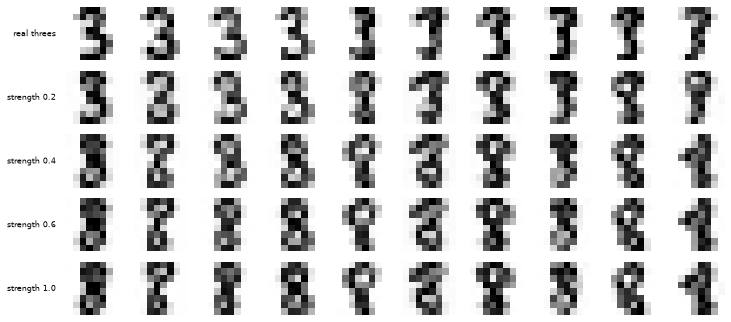

In [ ]:
src = test_x[test_y == 3][:30]                       # thirty real threes
want = torch.full((30,), 8)                          # the edit: "an eight"
print("strength  reads as 8  still reads as 3  distance to the original")
rows, titles = [src[:10]], ["real threes"]
for st in (0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0):
    out = sample(class_fn(want), (1, 8, 8), 30, 1.0, init=src, strength=st)      # w = 1: plain conditioning; try 3.0
    a = judge_probs(out).argmax(1)
    print(f"{st:8.1f} {(a == 8).float().mean().item():10.2f} {(a == 3).float().mean().item():16.2f} {(out.clamp(-1, 1) - src).flatten(1).norm(dim=1).mean().item():22.2f}")
    if st in (0.2, 0.4, 0.6, 1.0):
        rows.append(out[:10].clamp(-1, 1)); titles.append(f"strength {st}")
show_rows(rows, titles)

## 7. Inpainting: hide half of a digit and fill it in

After every denoising step the known half is put back, noised to the current level (lesson 6). With the digit's own label the completion usually reads as that digit; with the next digit's label the model has to choose between the label and the visible half.

prompt = own label: reads as the prompt 0.97, reads as the visible half's digit 0.97
prompt = next label: reads as the prompt 0.55, reads as the visible half's digit 0.30


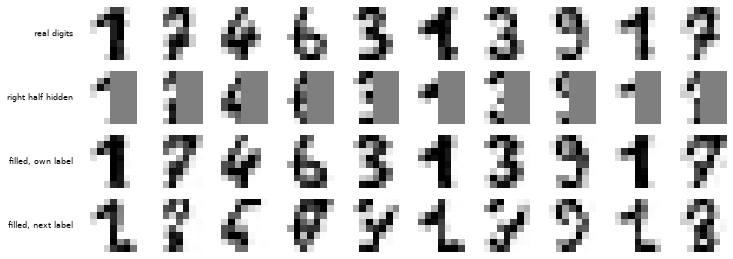

In [ ]:
lab, kn = test_y[:100], test_x[:100]                 # 100 real test digits; we hide their RIGHT half and let the model fill it
mask = torch.zeros(1, 8, 8); mask[..., :, 4:] = 1    # 1 = to be generated, 0 = known
def done(out):
    return mask * out.clamp(-1, 1) + (1 - mask) * kn
shown = kn[:10].clone(); shown[..., :, 4:] = 0.0
rows, titles = [kn[:10], shown], ["real digits", "right half hidden"]
for name, ll in (("own label", lab), ("next label", (lab + 1) % 10)):
    out = sample(class_fn(ll), (1, 8, 8), 100, 3.0, known=kn, mask=mask)       # the known pixels are put back after every step
    a = judge_probs(done(out)).argmax(1)
    print(f"prompt = {name}: reads as the prompt {(a == ll).float().mean().item():.2f}, reads as the visible half's digit {(a == lab).float().mean().item():.2f}")
    rows.append(done(out)[:10]); titles.append(f"filled, {name}")
show_rows(rows, titles)

## Try it yourself

1. In the cluster cell change the spread `S` to 0.3 and to 0.8. Where does the guidance sweep break down earlier?
2. In the training cell change the label dropout from `drop=0.1` to `0.3` (delete `t06_class.pt` first, or the saved model is loaded). Does the guidance sweep change?
3. In the sweep find the smallest scale with at least 99% fidelity. Pick it for a user who values variety; pick another for a user who values obedience. Write one sentence for each.
4. In the seed cell add a fourth seed. Is any neighbouring pair of scales in the first sweep within the seed noise?
5. In the editing cell change `1.0` to `3.0` (guidance in the edit). At which strength does the edit now succeed?
6. In the inpainting cell hide the left half instead (swap the columns of the mask). Does the model do as well?
7. Change `20` steps to `5` in the `sample` default and run the sweep again: guidance and the number of steps interact. Write down what you see.